In [1]:
# Author: Om Mohite

import os
from pathlib import Path
from getpass import getpass

from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

# Find and load the existing .env file
env_file = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidates = [
        folder / ".env",
        folder / "Data-Engineering-Real-World-Projects" / ".env",
    ]

    for candidate in candidates:
        if candidate.exists():
            env_file = candidate
            break

    if env_file:
        break

if env_file:
    load_dotenv(env_file)

db_password = os.getenv("DB_PASSWORD") or getpass("MySQL password: ")

# Connect to MySQL server
server_url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER", "root"),
    password=db_password,
    host=os.getenv("DB_HOST", "localhost"),
    port=int(os.getenv("DB_PORT", "3306")),
)

server_engine = create_engine(server_url, pool_pre_ping=True)

with server_engine.begin() as conn:
    conn.execute(text("CREATE DATABASE IF NOT EXISTS test_case_5"))

# Connect to the Test Case 5 database
engine = create_engine(
    server_url.set(database="test_case_5"),
    pool_pre_ping=True,
)

create_table_sql = """
CREATE TABLE IF NOT EXISTS daily_sales (
    sale_id INT PRIMARY KEY AUTO_INCREMENT,
    sale_date DATE NOT NULL,
    product_name VARCHAR(100),
    quantity INT NOT NULL,
    unit_price DECIMAL(10, 2) NOT NULL,
    total_amount DECIMAL(12, 2) NOT NULL
)
"""

with engine.begin() as conn:
    conn.execute(text(create_table_sql))
    tables = conn.execute(text("SHOW TABLES")).all()

print("Connected database: test_case_5")
print("Tables:", tables)

server_engine.dispose()

Connected database: test_case_5
Tables: [('daily_sales',)]


In [3]:
# Author: Om Mohite

import re
from pathlib import Path

import pandas as pd
from sqlalchemy import text

sql_candidates = [
    Path.cwd() / "test_case_5.sql",
    Path.cwd() / "Data-Engineering-Real-World-Projects" / "test_cases_5" / "test_case_5.sql",
]

sql_file = next((path for path in sql_candidates if path.exists()), None)

if sql_file is None:
    raise FileNotFoundError("Could not find test_case_5.sql.")

sql_script = sql_file.read_text(encoding="utf-8")

insert_statements = [
    statement.strip()
    for statement in sql_script.split(";")
    if re.match(
        r"\s*INSERT\s+INTO\s+daily_sales\b",
        statement,
        re.IGNORECASE,
    )
]

if not insert_statements:
    raise ValueError("No daily_sales INSERT statements found in test_case_5.sql.")

with engine.begin() as conn:
    conn.execute(text("TRUNCATE TABLE daily_sales"))

    for statement in insert_statements:
        conn.exec_driver_sql(statement)

with engine.connect() as conn:
    row_count = conn.execute(
        text("SELECT COUNT(*) FROM daily_sales")
    ).scalar_one()

    date_range = conn.execute(
        text("SELECT MIN(sale_date), MAX(sale_date) FROM daily_sales")
    ).one()

    preview = pd.read_sql(
        "SELECT * FROM daily_sales ORDER BY sale_date, sale_id LIMIT 5",
        con=conn,
    )

print("Rows loaded:", row_count)
print("Date range:", date_range[0], "to", date_range[1])
display(preview)

Rows loaded: 208
Date range: 2024-01-01 to 2026-01-14


,sale_id,sale_date,product_name,quantity,unit_price,total_amount
0,31,2024-01-01,Laptop,1,60000.0,60000.0
1,32,2024-01-01,Mouse,3,500.0,1500.0
2,33,2024-01-05,Mobile,2,20000.0,40000.0
3,34,2024-01-10,Headphones,4,2000.0,8000.0
4,35,2024-01-15,Keyboard,2,1500.0,3000.0


In [4]:
# Author: Om Mohite

import pandas as pd


def data_extraction(engine):
    df = pd.read_sql(
        "SELECT * FROM daily_sales",
        con=engine,
    )

    if df.empty:
        raise ValueError("daily_sales contains no records.")

    return df


def data_transformation(df):
    transformed_df = df.copy()

    transformed_df["sale_date"] = pd.to_datetime(
        transformed_df["sale_date"],
        errors="raise",
    )

    transformed_df["Day"] = transformed_df["sale_date"].dt.day
    transformed_df["Year"] = transformed_df["sale_date"].dt.year
    transformed_df["Month"] = transformed_df["sale_date"].dt.month

    return transformed_df


df = data_extraction(engine)
new_df = data_transformation(df)

print("Rows extracted:", len(df))
print("Rows transformed:", len(new_df))
display(new_df.head())

Rows extracted: 208
Rows transformed: 208


,sale_id,sale_date,product_name,quantity,unit_price,total_amount,Day,Year,Month
0,1,2026-01-01,Laptop,2,50000.0,100000.0,1,2026,1
1,2,2026-01-01,Mouse,5,500.0,2500.0,1,2026,1
2,3,2026-01-01,Keyboard,3,1200.0,3600.0,1,2026,1
3,4,2026-01-02,Laptop,1,50000.0,50000.0,2,2026,1
4,5,2026-01-02,Monitor,2,12000.0,24000.0,2,2026,1


In [5]:
# Author: Om Mohite

from sqlalchemy import text

daily_average = pd.read_sql(
    text("""
        SELECT
            sale_id,
            sale_date,
            AVG(total_amount) OVER (
                PARTITION BY sale_date
                ORDER BY sale_id
                ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
            ) AS daily_avg_sale
        FROM daily_sales
        ORDER BY sale_date, sale_id
    """),
    con=engine,
)

display(daily_average.head(10))

,sale_id,sale_date,daily_avg_sale
0,31,2024-01-01,60000.0
1,32,2024-01-01,30750.0
2,33,2024-01-05,40000.0
3,34,2024-01-10,8000.0
4,35,2024-01-15,3000.0
5,36,2024-01-20,65000.0
6,37,2024-01-25,18000.0
7,38,2024-01-30,3000.0
8,39,2024-02-02,62000.0
9,40,2024-02-05,57000.0


In [6]:
# Author: Om Mohite

monthly_trend = (
    new_df
    .groupby(["Year", "Month"], as_index=False)["total_amount"]
    .sum()
    .rename(columns={"total_amount": "monthly_revenue"})
    .sort_values(["Year", "Month"])
    .reset_index(drop=True)
)

monthly_trend["prev_month_revenue"] = (
    monthly_trend["monthly_revenue"].shift(1)
)

display(monthly_trend)

,Year,Month,monthly_revenue,prev_month_revenue
0,2024,1,198500.0,NaN
1,2024,2,295000.0,198500.0
2,2024,3,310700.0,295000.0
3,2024,4,258800.0,310700.0
4,2024,5,519700.0,258800.0
5,2024,6,264600.0,519700.0
6,2024,7,333600.0,264600.0
7,2024,8,327600.0,333600.0
8,2024,9,340050.0,327600.0
9,2024,10,567700.0,340050.0


In [7]:
# Author: Om Mohite

previous_revenue = monthly_trend["prev_month_revenue"].replace(0, pd.NA)

monthly_trend["mom_growth_percent"] = (
    (monthly_trend["monthly_revenue"] - monthly_trend["prev_month_revenue"])
    .div(previous_revenue)
    .mul(100)
)

display(monthly_trend)

,Year,Month,monthly_revenue,prev_month_revenue,mom_growth_percent
0,2024,1,198500.0,NaN,NaN
1,2024,2,295000.0,198500.0,48.614610
2,2024,3,310700.0,295000.0,5.322034
3,2024,4,258800.0,310700.0,-16.704216
4,2024,5,519700.0,258800.0,100.811437
5,2024,6,264600.0,519700.0,-49.086011
6,2024,7,333600.0,264600.0,26.077098
7,2024,8,327600.0,333600.0,-1.798561
8,2024,9,340050.0,327600.0,3.800366
9,2024,10,567700.0,340050.0,66.946037


Matplotlib is building the font cache; this may take a moment.


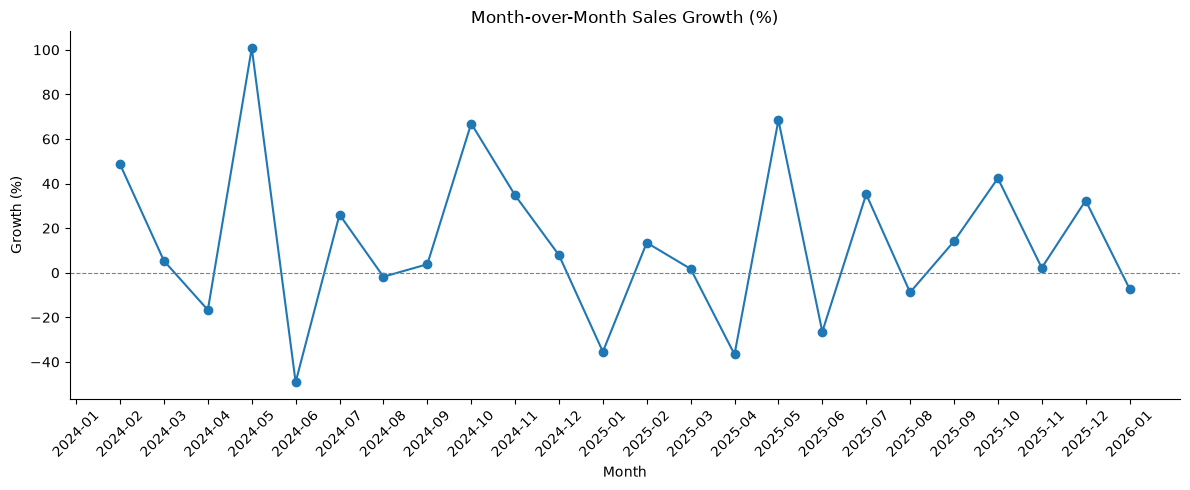

In [12]:
# Author: Om Mohite

import matplotlib.pyplot as plt

monthly_trend["Period"] = (
    monthly_trend["Year"].astype(str)
    + "-"
    + monthly_trend["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_trend["Period"],
    monthly_trend["mom_growth_percent"],
    marker="o",
)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Month-over-Month Sales Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

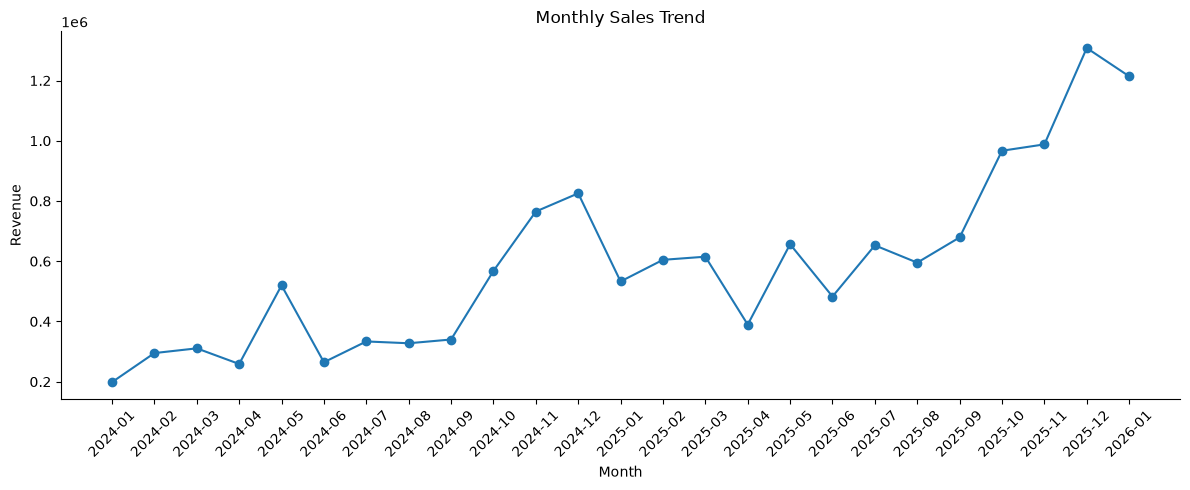

In [13]:
# Author: Om Mohite

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_trend["Period"],
    monthly_trend["monthly_revenue"],
    marker="o",
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [14]:
# Author: Om Mohite

validation_report = {
    "source_rows": len(df),
    "transformed_rows": len(new_df),
    "daily_average_rows": len(daily_average),
    "monthly_periods": len(monthly_trend),
    "missing_sale_dates": int(new_df["sale_date"].isna().sum()),
    "missing_daily_averages": int(daily_average["daily_avg_sale"].isna().sum()),
    "missing_monthly_revenue": int(monthly_trend["monthly_revenue"].isna().sum()),
}

display(pd.Series(validation_report, name="count").to_frame())

assert validation_report["source_rows"] == validation_report["transformed_rows"]
assert validation_report["daily_average_rows"] == validation_report["source_rows"]
assert validation_report["missing_sale_dates"] == 0
assert validation_report["missing_daily_averages"] == 0
assert validation_report["missing_monthly_revenue"] == 0
assert monthly_trend["Period"].is_monotonic_increasing

print("TEST CASE 5 VALIDATION PASSED")

,count
source_rows,208
transformed_rows,208
daily_average_rows,208
monthly_periods,25
missing_sale_dates,0
missing_daily_averages,0
missing_monthly_revenue,0


TEST CASE 5 VALIDATION PASSED
